# Import Data dan Library

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from sklearn.preprocessing import LabelEncoder

df=pd.read_csv("practical_data_marketing_growth_analytics.csv")
df

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,796,2025-02-14,Email,facebook,Mobile,6,2,0,0,0,0,0,49,1470,0,0
796,797,2025-01-21,Email,instagram,Mobile,5,10,0,1,1,361793,0,47,564,0,2
797,798,2025-01-11,Email,tiktok,Tablet,3,14,0,1,0,0,0,5,195,0,0
798,799,2025-02-19,Social Media,tiktok,Mobile,5,16,0,0,0,0,0,3,84,0,0


# Pengecekan Awal

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   user_id           800 non-null    int64
 1   first_visit_date  800 non-null    str  
 2   channel           800 non-null    str  
 3   source            800 non-null    str  
 4   device            800 non-null    str  
 5   sessions          800 non-null    int64
 6   page_views        800 non-null    int64
 7   bounce            800 non-null    int64
 8   add_to_cart       800 non-null    int64
 9   purchase          800 non-null    int64
 10  revenue           800 non-null    int64
 11  ad_cost           800 non-null    int64
 12  clicks            800 non-null    int64
 13  impressions       800 non-null    int64
 14  repeat_purchase   800 non-null    int64
 15  retention_month   800 non-null    int64
dtypes: int64(12), str(4)
memory usage: 125.8 KB


In [3]:
df.describe().round(2)

,user_id,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month
count,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00,800.00
mean,400.50,4.13,10.05,0.03,0.41,0.19,51254.88,13686.13,24.37,553.38,0.06,0.43
std,231.08,1.97,5.48,0.18,0.49,0.39,121909.73,23499.47,14.37,427.27,0.24,1.10
min,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,8.00,0.00,0.00
25%,200.75,3.00,5.00,0.00,0.00,0.00,0.00,0.00,11.00,208.75,0.00,0.00
50%,400.50,4.00,10.00,0.00,0.00,0.00,0.00,0.00,23.00,442.00,0.00,0.00
75%,600.25,6.00,15.00,0.00,1.00,0.00,0.00,21996.75,37.00,812.00,0.00,0.00
max,800.00,7.00,19.00,1.00,1.00,1.00,495675.00,79437.00,49.00,1911.00,1.00,5.00


## Cek duplikat

In [4]:
df[df.duplicated(keep=False)]

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month


## Cek konsistensi

In [5]:
df["channel"].value_counts()

channel
Paid Ads          251
Organic Search    198
Social Media      151
Email             125
Referral           75
Name: count, dtype: int64

In [6]:
df["source"].value_counts()

source
instagram    143
google       138
facebook     132
tiktok       130
email        130
direct       127
Name: count, dtype: int64

In [7]:
df["device"].value_counts()

device
Mobile     504
Desktop    262
Tablet      34
Name: count, dtype: int64

## Cek outlier

### Sessions

In [8]:
Q1 = df["sessions"].quantile(0.25)
Q3 = df["sessions"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["sessions"] < lower) |
    (df["sessions"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["sessions"].count())

Q1: 3.0
Q3: 6.0
IQR: 3.0
Lower Bound: -1.5
Upper Bound: 10.5
Jumlah Outlier: 0


### Page views

In [9]:
Q1 = df["page_views"].quantile(0.25)
Q3 = df["page_views"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["page_views"] < lower) |
    (df["page_views"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["page_views"].count())

Q1: 5.0
Q3: 15.0
IQR: 10.0
Lower Bound: -10.0
Upper Bound: 30.0
Jumlah Outlier: 0


### Bounce

In [10]:
Q1 = df["bounce"].quantile(0.25)
Q3 = df["bounce"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["bounce"] < lower) |
    (df["bounce"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["bounce"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 26


### Add_to_cart

In [11]:
Q1 = df["add_to_cart"].quantile(0.25)
Q3 = df["add_to_cart"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["add_to_cart"] < lower) |
    (df["add_to_cart"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["add_to_cart"].count())

Q1: 0.0
Q3: 1.0
IQR: 1.0
Lower Bound: -1.5
Upper Bound: 2.5
Jumlah Outlier: 0


### Purchase

In [12]:
Q1 = df["purchase"].quantile(0.25)
Q3 = df["purchase"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["purchase"] < lower) |
    (df["purchase"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["purchase"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 150


### Revenue

In [13]:
Q1 = df["revenue"].quantile(0.25)
Q3 = df["revenue"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["revenue"] < lower) |
    (df["revenue"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["revenue"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 150


### Ad_cost

In [14]:
Q1 = df["ad_cost"].quantile(0.25)
Q3 = df["ad_cost"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["ad_cost"] < lower) |
    (df["ad_cost"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["ad_cost"].count())

Q1: 0.0
Q3: 21996.75
IQR: 21996.75
Lower Bound: -32995.125
Upper Bound: 54991.875
Jumlah Outlier: 89


### Clicks

In [15]:
Q1 = df["clicks"].quantile(0.25)
Q3 = df["clicks"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["clicks"] < lower) |
    (df["clicks"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["clicks"].count())

Q1: 11.0
Q3: 37.0
IQR: 26.0
Lower Bound: -28.0
Upper Bound: 76.0
Jumlah Outlier: 0


### Impressions

In [16]:
Q1 = df["impressions"].quantile(0.25)
Q3 = df["impressions"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["impressions"] < lower) |
    (df["impressions"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["impressions"].count())

Q1: 208.75
Q3: 812.0
IQR: 603.25
Lower Bound: -696.125
Upper Bound: 1716.875
Jumlah Outlier: 7


### Repeat_purchase

In [17]:
Q1 = df["repeat_purchase"].quantile(0.25)
Q3 = df["repeat_purchase"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["repeat_purchase"] < lower) |
    (df["repeat_purchase"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["repeat_purchase"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 48


### Retention_month

In [18]:
Q1 = df["retention_month"].quantile(0.25)
Q3 = df["retention_month"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

value_outlier = df[
    (df["retention_month"] < lower) |
    (df["retention_month"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Jumlah Outlier:",value_outlier["retention_month"].count())

Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Jumlah Outlier: 150


# Cleaning Data

## Mengubah Tipe Data First_Visit

In [19]:
df['first_visit_date'] = pd.to_datetime(df['first_visit_date'])

# EDA

## Trend untuk beberapa variabel

### Trend User Baru

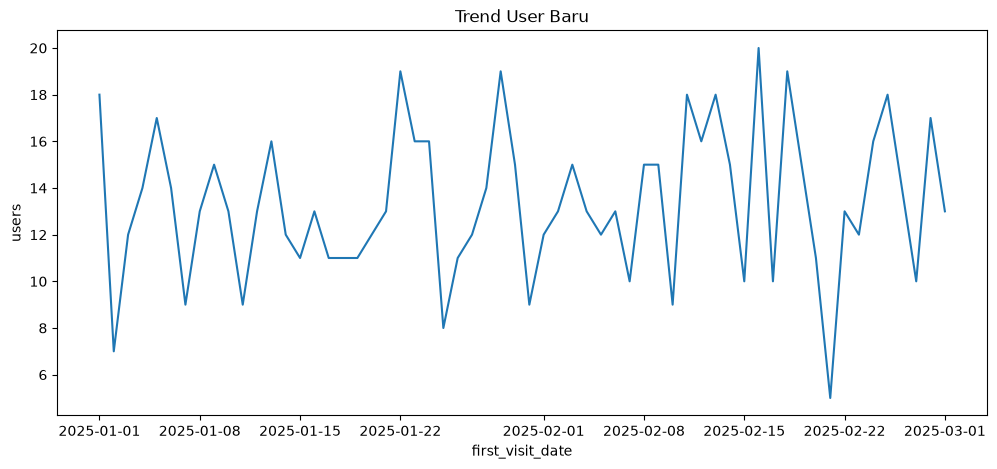

In [20]:
daily_user = (
    df.groupby('first_visit_date')
      .size()
      .reset_index(name='users')
)

plt.figure(figsize=(12,5))
sns.lineplot(data=daily_user, x='first_visit_date', y='users')

plt.title('Trend User Baru')
plt.show()

### Trend Revenue

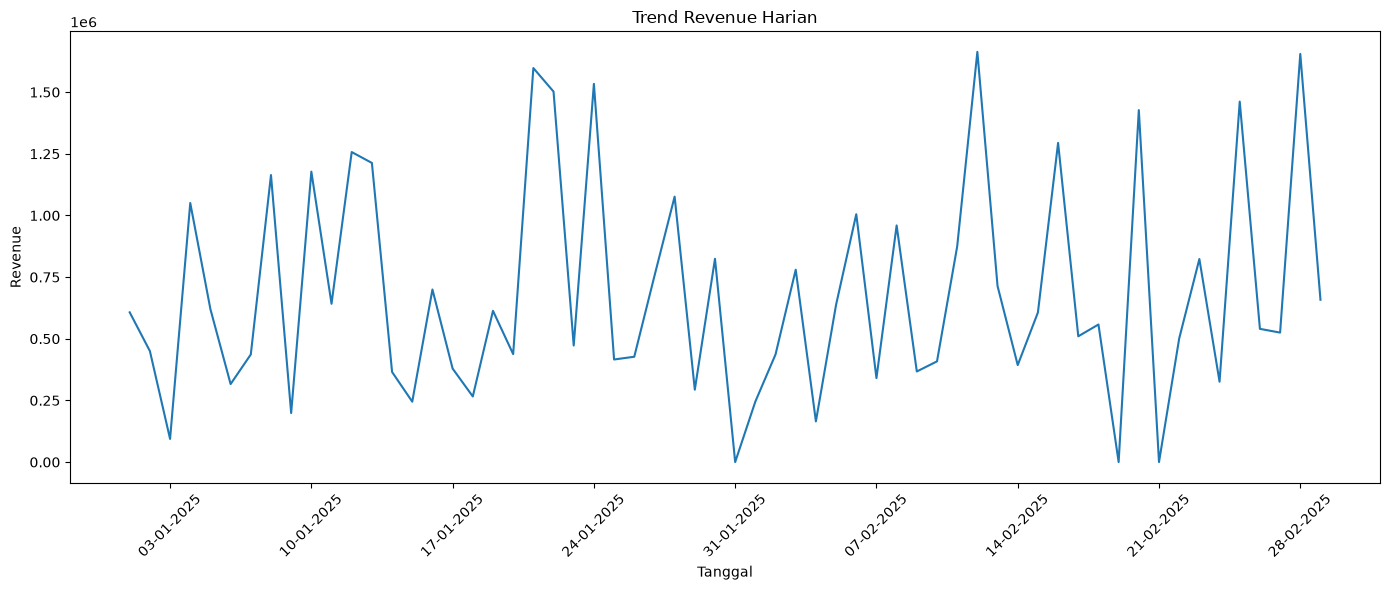

In [21]:
daily_revenue = (
    df.groupby('first_visit_date')['revenue']
      .sum()
      .reset_index()
)

plt.figure(figsize=(14,6))

sns.lineplot(
    data=daily_revenue,
    x='first_visit_date',
    y='revenue'
)

# tampilkan tanggal setiap 7 hari
plt.gca().xaxis.set_major_locator(
    mdates.DayLocator(interval=7)
)

# format tanggal
plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter('%d-%m-%Y')
)

plt.xticks(rotation=45)

plt.title('Trend Revenue Harian')
plt.xlabel('Tanggal')
plt.ylabel('Revenue')

plt.tight_layout()
plt.show()

## Univariat

### Kategorikal

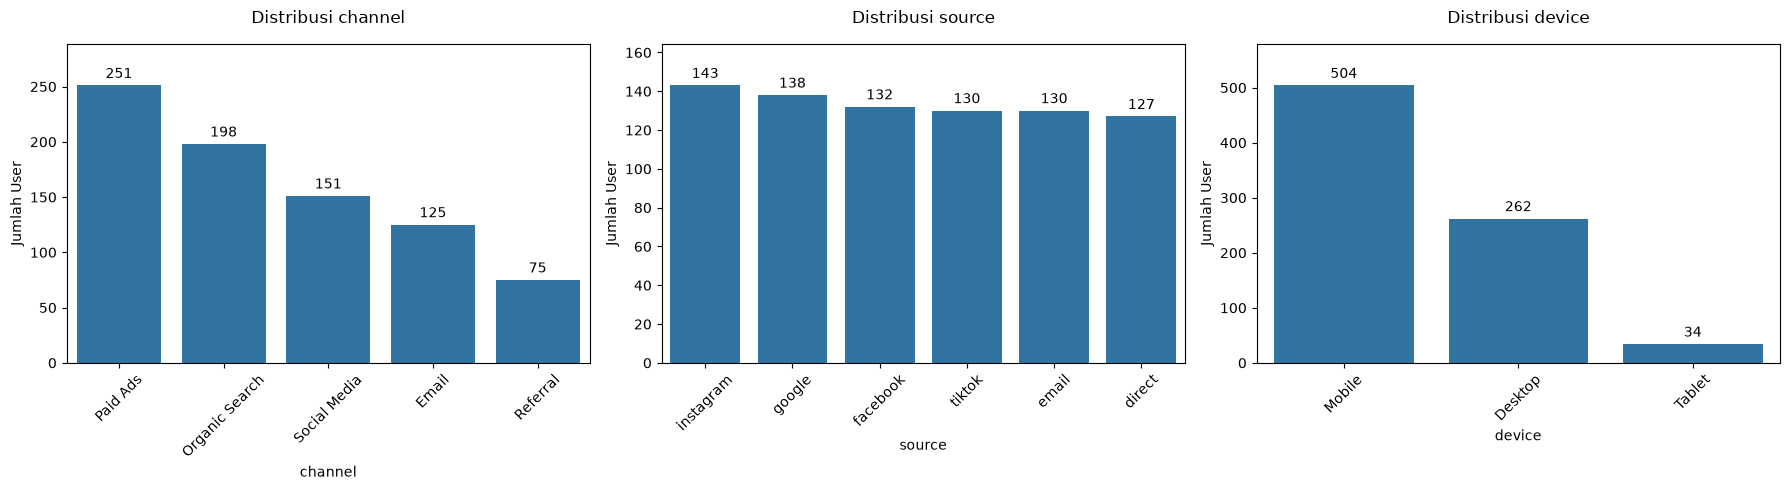

In [40]:
categorical_cols = ['channel', 'source', 'device']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, col in enumerate(categorical_cols):

    sns.countplot(
        data=df,
        x=col,
        ax=axes[i],
        order=df[col].value_counts().index
    )

    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Jumlah User')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].margins(y=0.15)
    axes[i].set_title(f'Distribusi {col}', pad=15)

    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fmt='%d',
            padding=3
        )

plt.tight_layout()
plt.show()

### Numeric

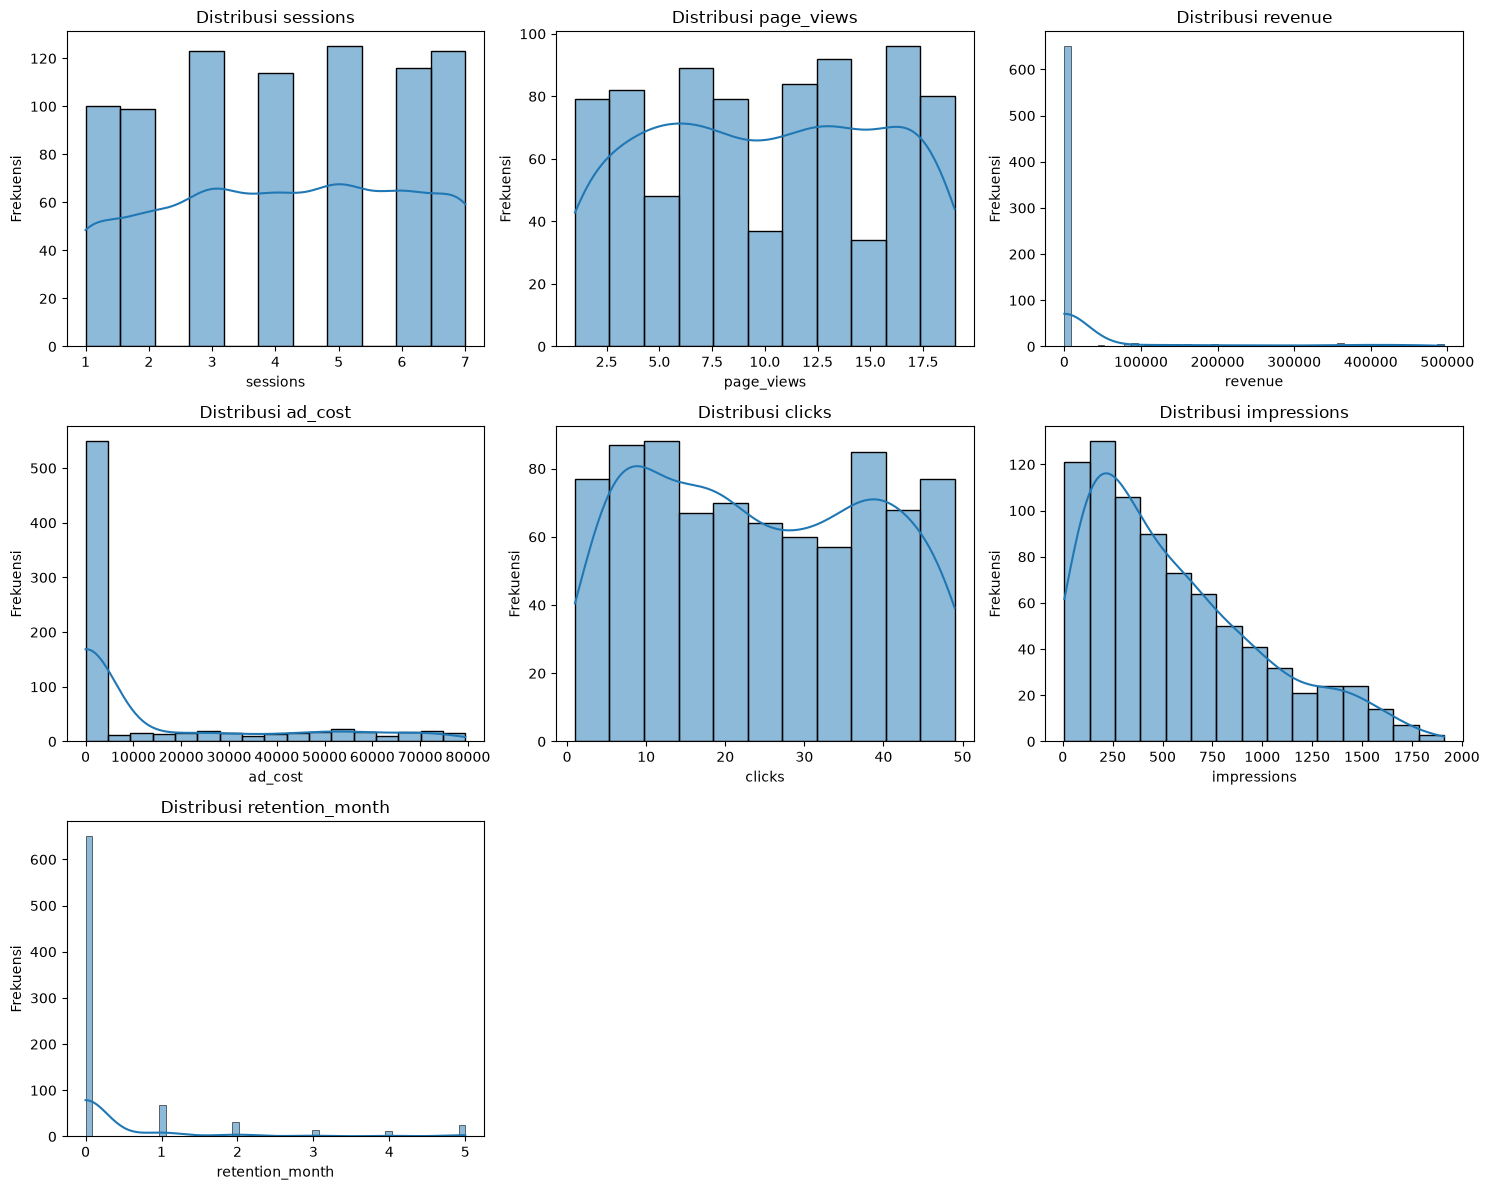

In [25]:
numerical_cols = [
    'sessions',
    'page_views',
    'revenue',
    'ad_cost',
    'clicks',
    'impressions',
    'retention_month'
]

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, col in enumerate(numerical_cols):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

# Menghapus subplot yang tidak terpakai
for j in range(len(numerical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Binary

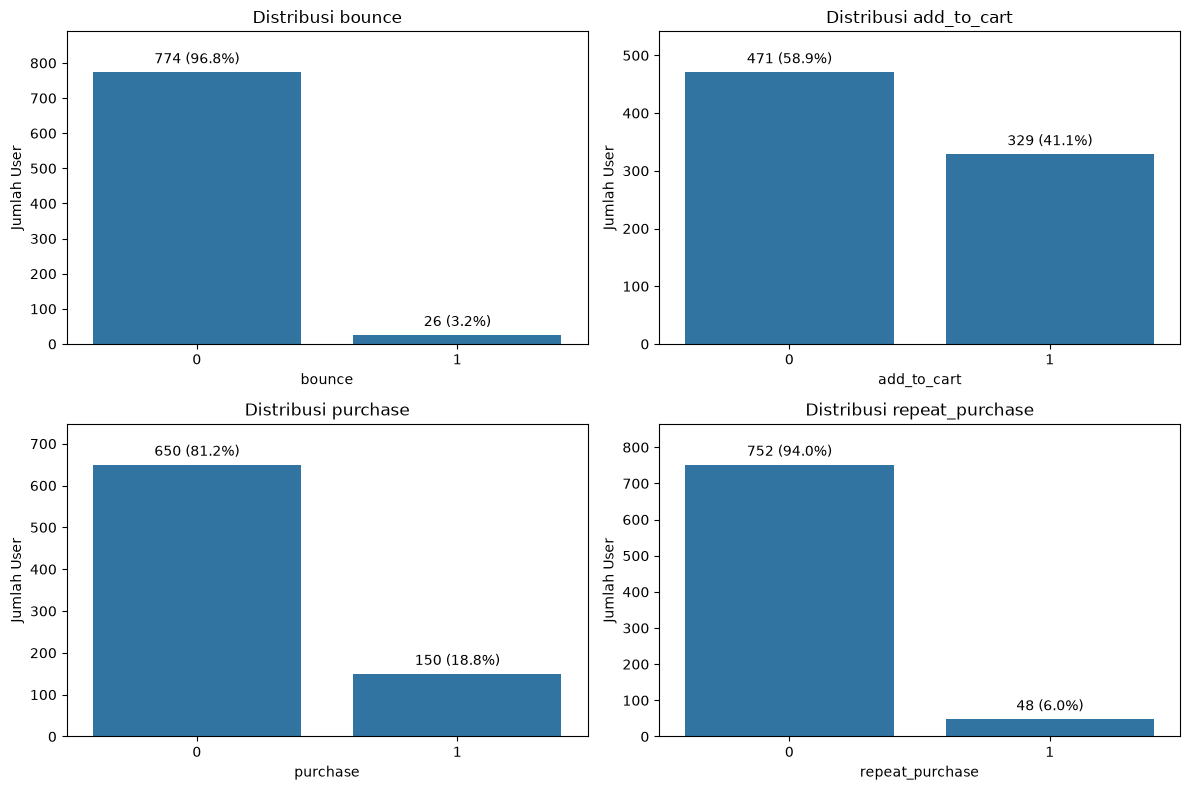

In [39]:
binary_cols = [
    'bounce',
    'add_to_cart',
    'purchase',
    'repeat_purchase'
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 8)
)

axes = axes.flatten()

for i, col in enumerate(binary_cols):

    sns.countplot(
        data=df,
        x=col,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribusi {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Jumlah User')

    total = len(df)

    # Tambahkan ruang di atas bar
    axes[i].margins(y=0.15)

    for container in axes[i].containers:

        labels = [
            f'{int(bar.get_height())} ({bar.get_height()/total*100:.1f}%)'
            for bar in container
        ]

        axes[i].bar_label(
            container,
            labels=labels,
            padding=4,
            fontsize=10
        )

plt.tight_layout()
plt.show()

## Bivariat

### Encoding variabel kategorikal sebelum mencari korelasi

In [30]:
categorical_cols = [
    'channel',
    'source',
    'device'
]

le = LabelEncoder()

for col in categorical_cols:
    df[col + '_encoded'] = le.fit_transform(df[col])

df.head()

,user_id,first_visit_date,channel,source,device,sessions,page_views,bounce,add_to_cart,purchase,revenue,ad_cost,clicks,impressions,repeat_purchase,retention_month,channel_encoded,source_encoded,device_encoded
0,1,2025-02-17,Referral,instagram,Mobile,7,4,0,1,1,401318,0,40,880,0,2,3,4,1
1,2,2025-01-05,Referral,facebook,Mobile,3,5,0,0,0,0,0,12,264,0,0,3,2,1
2,3,2025-01-26,Referral,tiktok,Mobile,4,5,0,0,0,0,0,3,72,0,0,3,5,1
3,4,2025-02-24,Paid Ads,facebook,Mobile,4,2,0,1,0,0,18215,16,320,0,0,2,2,1
4,5,2025-01-04,Referral,instagram,Mobile,1,18,0,0,0,0,0,44,792,0,0,3,4,1


### Korelasi

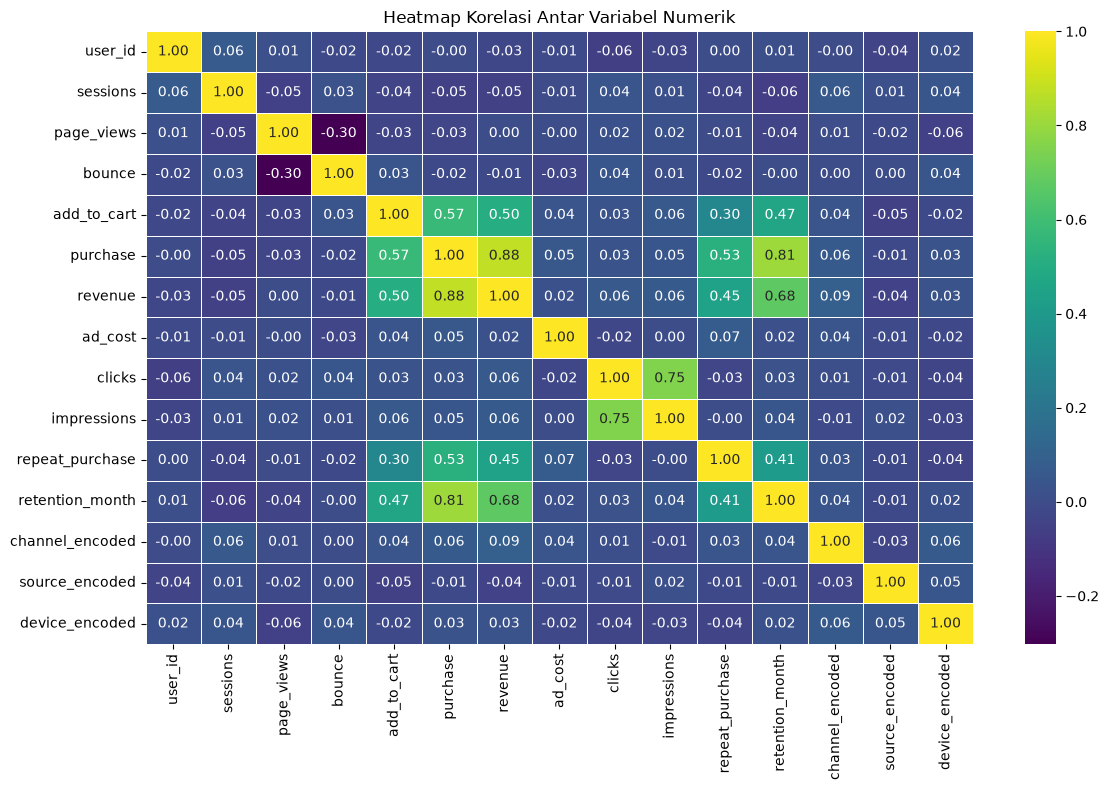

In [31]:
# Ambil kolom numerik
numeric_df = df.select_dtypes(include='number')

# Hitung korelasi
corr = numeric_df.corr()

# Buat heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='viridis',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Heatmap Korelasi Antar Variabel Numerik')
plt.tight_layout()
plt.show()

## Multivariat

### Purchase Rate berdasarkan Device dan Channel

In [32]:
channel_device = (
    df.groupby(['channel', 'device'])
      .agg(
          users=('user_id', 'count'),
          purchase=('purchase', 'sum')
      )
      .reset_index()
)

channel_device['purchase_rate'] = (
    channel_device['purchase'] /
    channel_device['users'] * 100
)

channel_device

,channel,device,users,purchase,purchase_rate
0,Email,Desktop,38,6,15.789474
1,Email,Mobile,83,13,15.662651
2,Email,Tablet,4,1,25.000000
3,Organic Search,Desktop,70,8,11.428571
4,Organic Search,Mobile,124,22,17.741935
5,Organic Search,Tablet,4,1,25.000000
6,Paid Ads,Desktop,87,17,19.540230
7,Paid Ads,Mobile,155,33,21.290323
8,Paid Ads,Tablet,9,1,11.111111
9,Referral,Desktop,25,7,28.000000


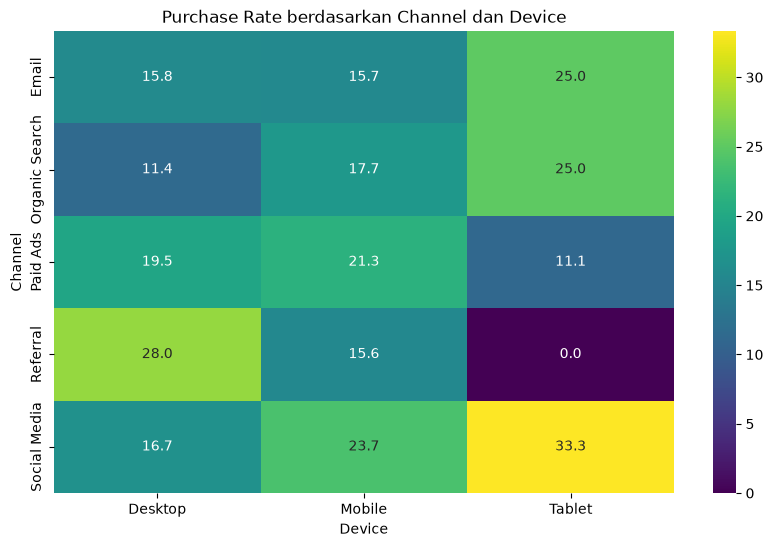

In [33]:
pivot_cd = channel_device.pivot(
    index='channel',
    columns='device',
    values='purchase_rate'
)

plt.figure(figsize=(10,6))

sns.heatmap(
    pivot_cd,
    annot=True,
    fmt='.1f',
    cmap='viridis'
)

plt.title('Purchase Rate berdasarkan Channel dan Device')
plt.xlabel('Device')
plt.ylabel('Channel')
plt.show()

### Channel x Source x Purchase

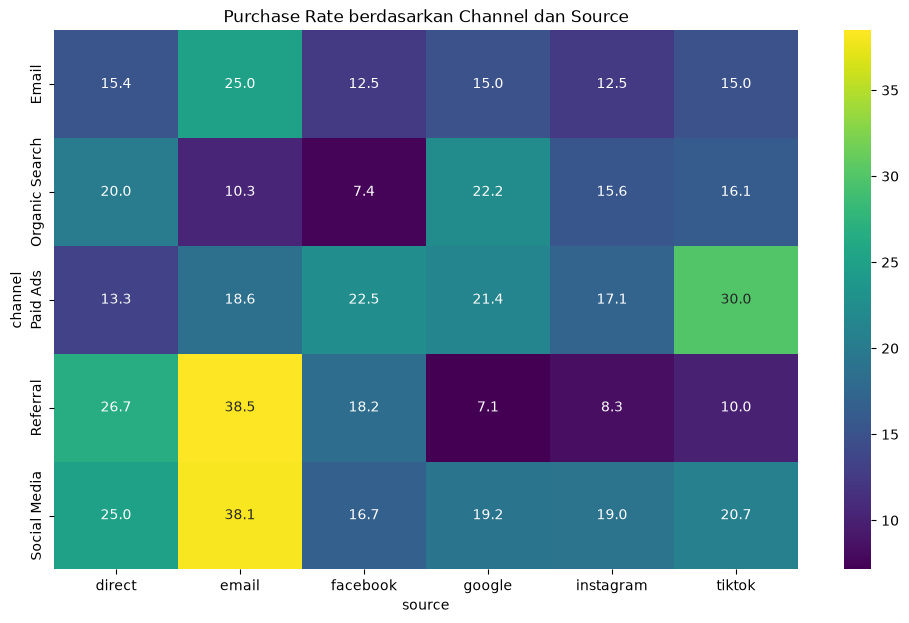

In [34]:
channel_source = (
    df.groupby(['channel', 'source'])
      .agg(
          users=('user_id', 'count'),
          purchase=('purchase', 'sum')
      )
      .reset_index()
)

channel_source['purchase_rate'] = (
    channel_source['purchase'] /
    channel_source['users'] * 100
)

pivot_cs = channel_source.pivot(
    index='channel',
    columns='source',
    values='purchase_rate'
)

plt.figure(figsize=(12,7))

sns.heatmap(
    pivot_cs,
    annot=True,
    fmt='.1f',
    cmap='viridis'
)

plt.title('Purchase Rate berdasarkan Channel dan Source')
plt.show()

### Impressions dan Clicks berdasarkan Purchase

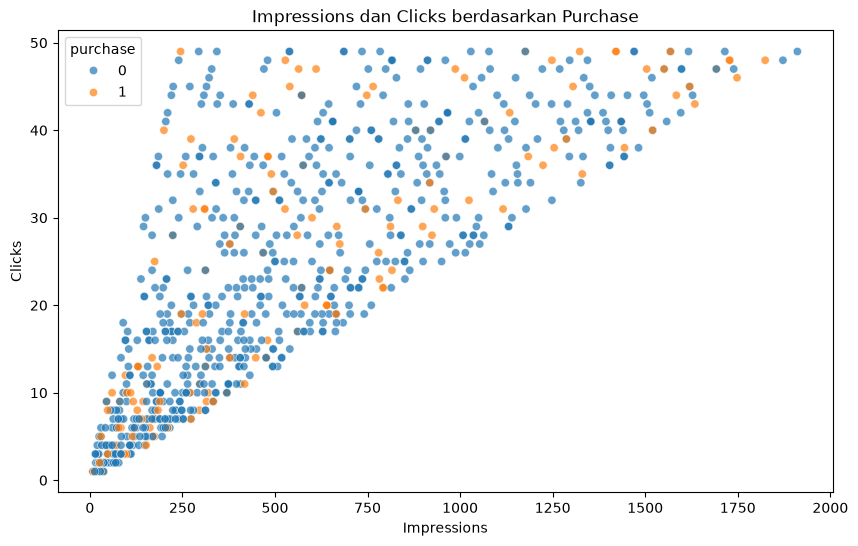

In [35]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='impressions',
    y='clicks',
    hue='purchase',
    alpha=0.7
)

plt.title('Impressions dan Clicks berdasarkan Purchase')
plt.xlabel('Impressions')
plt.ylabel('Clicks')
plt.show()